# Varlen Gated DeltaNet v2 (SM75 Turing / Tesla T4) — Build, Verify, Nsight Compute & Benchmark

End-to-end guide on **NVIDIA Tesla T4 (SM75)** (Google Colab / Kaggle / local CUDA GPU):
1. Verify GPU, CUDA, PyTorch environment and initialize **NVIDIA CUTLASS**.
2. Build the CUDA/CuTe extension and package a `.whl` into `wheels/`.
3. Verify numerical correctness (`tests/test_correctness.py`: Sub-Ops, `Chunkwise == Token-by-Token Recurrence`, Decode `L=1`, E2E `DeltaBlock` Prefill->Decode Handoff, CUDAGraph & API Guards).
4. **NVIDIA Nsight Compute (`ncu`) Profiling** — inspect kernel occupancy, SM throughput, DRAM bandwidth, and registers per thread upfront before full benchmarks.
5. **Fast Benchmark vs PyTorch Eager & `torch.compile` (`--skip-external`)** — check training & inference speed against PyTorch baselines immediately without waiting for FLA/NVLabs Triton JIT compilation.
6. Install optional open-source baselines (`FLA`, `NVLabs GatedDeltaNet-2`).
7. **Full Benchmarks vs Open-Source Baselines** — generate comparison tables & plots (`assets/training_benchmark.png`, `assets/inference_benchmark.png`).


## 1. Check GPU & Prepare Source / CUTLASS


In [1]:
import os, sys

if not os.path.isfile("setup.py") and not os.path.isdir("Varlen-Gated-DeltaNet"):
    !git clone --recursive --depth 1 https://github.com/CBG6682/Varlen-Gated-DeltaNet.git

if os.path.isdir("Varlen-Gated-DeltaNet"):
    %cd Varlen-Gated-DeltaNet
elif os.path.basename(os.getcwd()) == "benchmark":
    %cd ..

print("Working directory:", os.getcwd())

import torch
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available(), "| CUDA runtime:", torch.version.cuda)
if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0), "| Capability:", torch.cuda.get_device_capability(0))

!nvidia-smi


Cloning into 'Varlen-Gated-DeltaNet'...
remote: Enumerating objects: 43, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (37/37), done.
remote: Total 43 (delta 7), reused 23 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (43/43), 1.24 MiB | 21.50 MiB/s, done.
Resolving deltas: 100% (7/7), done.
Submodule 'third_party/cutlass' (https://github.com/NVIDIA/cutlass.git) registered for path 'third_party/cutlass'
Cloning into '/content/Varlen-Gated-DeltaNet/third_party/cutlass'...
remote: Enumerating objects: 47039, done.        
remote: Counting objects: 100% (765/765), done.        
remote: Compressing objects: 100% (489/489), done.        
remote: Total 47039 (delta 432), reused 289 (delta 276), pack-reused 46274 (from 3)        
Receiving objects: 100% (47039/47039), 80.16 MiB | 26.91 MiB/s, done.
Resolving deltas: 100% (34652/34652), done.
Submodule path 'third_party/cutlass': checked out 'af951046cd9cac9301d8e3e90863fd8d7edc9fa9'
/content

In [2]:
%%bash
set -e
if [ ! -f "third_party/cutlass/include/cute/tensor.hpp" ]; then
    echo "Initializing NVIDIA CUTLASS submodule in third_party/cutlass..."
    git submodule update --init --depth 1 third_party/cutlass
else
    echo "CUTLASS headers already exist in third_party/cutlass/include."
fi


CUTLASS headers already exist in third_party/cutlass/include.


## 2. Install Prebuilt Wheel or Build Extension (`wheels/`)
Checks `wheels/*.whl` first and installs it directly if compatible with the current Python/CUDA runtime; otherwise builds `_C*.so` from source and saves a new `.whl` into `wheels/`.


In [3]:
%%bash
set -euo pipefail

WHEEL_FILE=$(ls wheels/*.whl 2>/dev/null | head -n 1 || true)
USE_PREBUILT=0

if [ -n "$WHEEL_FILE" ] && [ "${FORCE_REBUILD:-0}" != "1" ]; then
    echo "Found prebuilt wheel: $WHEEL_FILE"
    python -m pip install -q --force-reinstall --no-deps "$WHEEL_FILE"
    if python -c "import torch, deltanet_v2; from deltanet_v2 import _C; print('Loaded prebuilt wheel:', _C.__file__)" 2>/dev/null; then
        USE_PREBUILT=1
    else
        echo "Prebuilt wheel is incompatible with current Python/PyTorch; falling back to source build..."
    fi
fi

if [ "$USE_PREBUILT" -eq 0 ]; then
    export MAX_JOBS=2
    export VERBOSE=1
    export TORCH_EXTENSIONS_VERBOSE=1
    pip install -q ninja wheel setuptools

    rm -rf build dist deltanet_v2/_C*.so
    FORCE_REBUILD=1 python setup.py build_ext --inplace -v

    rm -f wheels/*.whl
    FORCE_REBUILD=0 python -m pip wheel -v --no-deps --no-build-isolation -w wheels .
    FORCE_REBUILD=0 python -m pip install -v --no-deps --no-build-isolation -e .
    ls -lh wheels/*.whl deltanet_v2/_C*.so
fi


[setup.py] FORCE_REBUILD=1 requested: Recompiling CUDA extension from source...
[setup.py] Found dedicated CUTLASS in third_party: /content/Varlen-Gated-DeltaNet/third_party/cutlass/include
running build_ext
building 'deltanet_v2._C' extension
creating /content/Varlen-Gated-DeltaNet/build/temp.linux-x86_64-cpython-313/content/Varlen-Gated-DeltaNet/src
[1/13] c++ -MMD -MF /content/Varlen-Gated-DeltaNet/build/temp.linux-x86_64-cpython-313/content/Varlen-Gated-DeltaNet/src/binding.o.d -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -g -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -g -fwrapv -O2 -fPIC -I/content/Varlen-Gated-DeltaNet/include -I/content/Varlen-Gated-DeltaNet/third_party/cutlass/include -I/usr/local/lib/python3.13/dist-packages/torch/include -I/usr/local/lib/python3.13/dist-packages/torch/include/torch/csrc/api/include -I/usr/local/cuda/include -I/usr/include/p

  Running command Preparing metadata (pyproject.toml)
  [setup.py] Pre-compiled extension found: _C.cpython-313-x86_64-linux-gnu.so. Skipping compilation.
  [setup.py] (Set FORCE_REBUILD=1 to recompile from source).
  running dist_info
  creating /tmp/pip-modern-metadata-d2mn5mtp/deltanet_v2.egg-info
  writing /tmp/pip-modern-metadata-d2mn5mtp/deltanet_v2.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-modern-metadata-d2mn5mtp/deltanet_v2.egg-info/dependency_links.txt
  writing requirements to /tmp/pip-modern-metadata-d2mn5mtp/deltanet_v2.egg-info/requires.txt
  writing top-level names to /tmp/pip-modern-metadata-d2mn5mtp/deltanet_v2.egg-info/top_level.txt
  writing manifest file '/tmp/pip-modern-metadata-d2mn5mtp/deltanet_v2.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-modern-metadata-d2mn5mtp/deltanet_v2.egg-info/SOURCES.txt'
  adding license file 'LICENSE'
  writing manifest file '/tmp/pip-modern-metadata-d2mn5mtp/deltanet_v2.egg-info/SOURCES.txt'
  creating '/tm

## 3. Correctness Verification (Sub-Ops, Cross-Check, Decode `L=1` & E2E `DeltaBlock`)
Verifies GDN-2 sub-ops (`block_ops_fwd/bwd`, `proj_conv_prep_fwd/bwd`), mandatory cross-check `Chunkwise == Token-by-Token Recurrence`, full `apply_deltablock` (with `ShortConv1D`, channel-wise decay, `beta_guard`, `allow_neg_eigval`, Option 5A PreNorm SwiGLU MLP, zero-len edge cases), super-fused decode `apply_deltablock_infer` (FP32 `past_states` + FP16 `conv_state`), Prefill->Decode handoff, CUDA graphs, and API guards.


In [4]:
!python -u tests/test_correctness.py



########################################################################
# SUITE 1: Varlen Forward & Backward Kernels (Sub-Ops, Cross-Check & Full Block)
########################################################################


  [train/block_ops] L=193 D=768
    status tensor               | kernel vs fp32           | base16 vs fp32           | grp(worst) k b
    [PASS] rmsnorm eval==train             
    [PASS] rmsnorm out          | 2.08e-04 1.000000 1.9e-03 | 2.94e-04 1.000000 3.2e-03 | grp 2.26e-04 3.83e-04
    [PASS] rmsnorm dx           | 2.93e-04 1.000000 6.2e-03 | 3.59e-04 1.000000 8.9e-03
    [PASS] rmsnorm dw           | 2.95e-04 1.000000 2.0e-02 | 4.14e-04 1.000000 2.3e-02
    [PASS] res_rmsnorm eval==train         
    [PASS] res_rmsnorm x_norm   | 3.06e-04 1.000000 3.3e-03 | 3.69e-04 1.000000 3.4e-03 | grp 3.33e-04 4.10e-04
    [PASS] res_rmsnorm dh       | 2.93e-04 1.000000 3.6e-03 | 3.89e-04 1.000000 6.1e-03
    [PASS] res_rmsnorm dw       | 3.76e-04 1.000000 1.7e-02

## 4. NVIDIA Nsight Compute (`ncu`) Profiling (`.ncu-rep` in `benchmark/`)
Run immediately after correctness verification so SM throughput, DRAM bandwidth, achieved occupancy, and register/SMEM usage of every GDN-2 CUDA kernel can be inspected before running long benchmarks.
- **Proj/Conv Prep:** `kernel_fused_conv_act_l2_transpose_fwd/bwd`, `kernel_fused_gates_decay_betaguard_transpose_fwd`, `kernel_fused_conv_dx_transpose_bwd`, `kernel_fused_gates_decay_transpose_bwd`
- **WY / Scan / Output:** `kernel_chunk_wy_T_solve_fwd`, `kernel_chunk_wy_YU_fwd`, `kernel_chunk_scan_fwd/bwd`, `kernel_output_combine_fwd`, `kernel_out_norm_swiglu_transpose_bwd`, `kernel_output_combine_dR_dS_dQinter_bwd`, `kernel_output_combine_intra_dqk_bwd`, `kernel_chunk_wy_dA_dT_bwd`, `kernel_chunk_wy_intra_T_bwd`
- **Super-Fused Decode:** `kernel_deltanet_infer` *(5 decode cases: `b1_gqa2`..`b1024_mha`)*

> Note: On some cloud containers without hardware counter permissions for `ncu`, the command may report `ERR_NVGPUCTRPERM`.


In [5]:
%%bash
set -e
if ! command -v ncu &> /dev/null; then
    echo "[INFO] NVIDIA Nsight Compute (ncu) not found in PATH."
    exit 0
fi

NCU_SCRIPT='import sys, math, torch
from deltanet_v2 import DeltaBlock, custom_ops

kname = sys.argv[1]
dev = torch.device("cuda")
torch.manual_seed(42)

if kname == "kernel_deltanet_infer":
    cases = [
        ("b1_gqa2", 1, 8, 4),
        ("b16_gqa2", 16, 8, 4),
        ("b64_gqa2", 64, 8, 4),
        ("b256_gqa2", 256, 8, 4),
        ("b1024_mha", 1024, 8, 8),
    ]
    for _, B, hq, hkv in cases:
        d_model = 768
        blk = DeltaBlock(d_model, hq, hkv, d_k=64, d_v=64, hidden_dim=d_model * 4).to(dev).half().eval()
        x = torch.randn(B, d_model, device=dev, dtype=torch.float16)
        past = (torch.randn(B, hkv, 64, 64, device=dev) * 0.1).float().contiguous()
        conv_s = torch.randn(B, 3, (hq + 2 * hkv) * 64, device=dev, dtype=torch.float16)
        custom_ops.deltablock_infer(
            x, past, conv_s,
            blk.W_proj.weight, blk.conv_weight, blk.A_log, blk.dt_bias,
            blk.o_norm_weight, blk.W_out.weight,
            blk.norm1_weight, blk.norm2_weight, blk.mlp_W_gate_up.weight, blk.mlp_W_down.weight,
            hq, hkv, 64, 64, 4, blk.scale, blk.eps, False, True,
        )
else:
    train_cases = [
        ("short_b1", [128]),
        ("short_b16", [128] * 16),
        ("skewed_b4", [257, 512, 1024, 2048]),
        ("long_b1", [4096]),
    ]
    hq, hkv = 16, 4
    d_k, d_v, conv_size, chunk_size = 64, 64, 4, 64
    d_qkv = (hq + 2 * hkv) * 64
    total_proj = (hq + 3 * hkv) * 64 + (2 * hkv + hq) * 64
    scale = 1.0 / math.sqrt(d_k)
    for _, lens in train_cases:
        B = len(lens)
        L = sum(lens)
        cu = torch.tensor([0] + torch.cumsum(torch.tensor(lens), 0).tolist(), dtype=torch.int32, device=dev)
        proj = (torch.randn(L, total_proj, device=dev) * 0.4).half().contiguous()
        conv_w = (torch.randn(conv_size, d_qkv, device=dev) * 0.3).half().contiguous()
        A_log = torch.randn(hkv, device=dev, dtype=torch.float32)
        dt_bias = torch.randn(hkv, d_k, device=dev, dtype=torch.float32)
        o_norm_w = torch.ones(d_v, device=dev, dtype=torch.float16)
        past = (torch.randn(B, hkv, 64, 64, device=dev) * 0.1).float().contiguous()
        past_cs = torch.zeros(B, conv_size - 1, d_qkv, device=dev, dtype=torch.float16)

        q_h, k_h, v_h, b_eff_h, w_h, G_log2_h, _, q_inv, k_inv = custom_ops.proj_conv_prep_fwd(
            proj, conv_w, A_log, dt_bias, past_cs, cu,
            hq, hkv, d_k, d_v, conv_size, chunk_size, scale, False, True, True, True,
        )
        if kname.startswith("kernel_fused_conv_") and kname.endswith("_fwd"):
            pass
        elif kname.startswith("kernel_fused_gates_") and kname.endswith("_fwd"):
            pass
        elif kname in ("kernel_fused_conv_act_l2_transpose_bwd", "kernel_fused_conv_dx_transpose_bwd", "kernel_fused_gates_decay_transpose_bwd"):
            d_proj = torch.zeros_like(proj)
            custom_ops.proj_conv_prep_bwd(
                torch.randn_like(q_h), torch.randn_like(k_h), torch.randn_like(v_h),
                torch.randn_like(b_eff_h), torch.randn_like(w_h), torch.randn_like(G_log2_h),
                proj, conv_w, A_log, dt_bias, past_cs, q_inv, k_inv, cu, d_proj,
                hq, hkv, d_k, d_v, conv_size, chunk_size, scale, False, True,
            )
        elif kname in ("kernel_chunk_wy_T_solve_fwd", "kernel_chunk_wy_YU_fwd"):
            custom_ops.chunk_wy_fwd(k_h, v_h, b_eff_h, w_h, G_log2_h, cu, chunk_size, True)
        elif kname == "kernel_chunk_scan_fwd":
            Y, U, _ = custom_ops.chunk_wy_fwd(k_h, v_h, b_eff_h, w_h, G_log2_h, cu, chunk_size, True)
            custom_ops.chunk_scan_fwd(Y, U, k_h, G_log2_h, past, cu, chunk_size)
        elif kname == "kernel_output_combine_fwd":
            Y, U, _ = custom_ops.chunk_wy_fwd(k_h, v_h, b_eff_h, w_h, G_log2_h, cu, chunk_size, True)
            S_list, R_list, _ = custom_ops.chunk_scan_fwd(Y, U, k_h, G_log2_h, past, cu, chunk_size)
            custom_ops.output_combine_fwd(q_h, k_h, G_log2_h, S_list, R_list, proj, o_norm_w, cu, hq, hkv, d_k, d_v, chunk_size, 1e-5, True)
        elif kname in ("kernel_out_norm_swiglu_transpose_bwd", "kernel_output_combine_dR_dS_dQinter_bwd", "kernel_output_combine_intra_dqk_bwd"):
            Y, U, _ = custom_ops.chunk_wy_fwd(k_h, v_h, b_eff_h, w_h, G_log2_h, cu, chunk_size, True)
            S_list, R_list, _ = custom_ops.chunk_scan_fwd(Y, U, k_h, G_log2_h, past, cu, chunk_size)
            out_tok, O_raw, o_rstd = custom_ops.output_combine_fwd(q_h, k_h, G_log2_h, S_list, R_list, proj, o_norm_w, cu, hq, hkv, d_k, d_v, chunk_size, 1e-5, True)
            custom_ops.output_combine_bwd(
                torch.randn_like(out_tok), O_raw, o_rstd, proj, o_norm_w, q_h, k_h, G_log2_h, S_list, R_list, cu, torch.zeros_like(proj),
                hq, hkv, d_k, d_v, chunk_size,
            )
        elif kname == "kernel_chunk_scan_bwd":
            Y, U, _ = custom_ops.chunk_wy_fwd(k_h, v_h, b_eff_h, w_h, G_log2_h, cu, chunk_size, True)
            S_list, R_list, fs = custom_ops.chunk_scan_fwd(Y, U, k_h, G_log2_h, past, cu, chunk_size)
            custom_ops.chunk_scan_bwd(
                torch.randn_like(S_list), torch.randn_like(R_list), Y, k_h, G_log2_h, cu, torch.randn_like(fs), True, chunk_size,
            )
        elif kname in ("kernel_chunk_wy_dA_dT_bwd", "kernel_chunk_wy_intra_T_bwd"):
            Y, U, A_list = custom_ops.chunk_wy_fwd(k_h, v_h, b_eff_h, w_h, G_log2_h, cu, chunk_size, True)
            S_list, R_list, fs = custom_ops.chunk_scan_fwd(Y, U, k_h, G_log2_h, past, cu, chunk_size)
            dS_next, dR_tot, _ = custom_ops.chunk_scan_bwd(
                torch.randn_like(S_list), torch.randn_like(R_list), Y, k_h, G_log2_h, cu, torch.randn_like(fs), True, chunk_size,
            )
            custom_ops.chunk_wy_bwd(
                dR_tot, R_list, S_list, dS_next, A_list, k_h, v_h, b_eff_h, w_h, G_log2_h,
                torch.randn_like(k_h), torch.randn_like(G_log2_h), cu, chunk_size,
            )

torch.cuda.synchronize()'

echo "$NCU_SCRIPT" > benchmark/_ncu_profile_target.py

KERNELS=(
    "kernel_fused_conv_act_l2_transpose_fwd"
    "kernel_fused_gates_decay_betaguard_transpose_fwd"
    "kernel_chunk_wy_T_solve_fwd"
    "kernel_chunk_wy_YU_fwd"
    "kernel_chunk_scan_fwd"
    "kernel_output_combine_fwd"
    "kernel_out_norm_swiglu_transpose_bwd"
    "kernel_output_combine_dR_dS_dQinter_bwd"
    "kernel_output_combine_intra_dqk_bwd"
    "kernel_chunk_scan_bwd"
    "kernel_chunk_wy_dA_dT_bwd"
    "kernel_chunk_wy_intra_T_bwd"
    "kernel_fused_conv_act_l2_transpose_bwd"
    "kernel_fused_conv_dx_transpose_bwd"
    "kernel_fused_gates_decay_transpose_bwd"
    "kernel_deltanet_infer"
)

for KNAME in "${KERNELS[@]}"; do
    echo "=== Profiling ${KNAME} (multi-case + embedded source) ==="
    ncu --set full --import-source yes --source-folders .,src,include -k "regex:${KNAME}" -f -o "benchmark/${KNAME}" python benchmark/_ncu_profile_target.py "${KNAME}" || true
done

rm -f benchmark/_ncu_profile_target.py
ls -lh benchmark/*.ncu-rep 2>/dev/null || echo "No .ncu-rep files generated."


=== Profiling kernel_fused_conv_act_l2_transpose_fwd (multi-case + embedded source) ===
==PROF== Connected to process 6643 (/usr/bin/python3.13)
==PROF== Profiling "kernel_fused_conv_act_l2_transpose_fwd": 0%....50%....100% - 33 passes
==PROF== Profiling "kernel_fused_conv_act_l2_transpose_fwd": 0%....50%....100% - 33 passes
==PROF== Profiling "kernel_fused_conv_act_l2_transpose_fwd": 0%....50%....100% - 33 passes
==PROF== Profiling "kernel_fused_conv_act_l2_transpose_fwd": 0%....50%....100% - 33 passes
==PROF== Disconnected from process 6643
==WARNING== No source files were imported. Check that the target application was compiled with -lineinfo.
==PROF== Report: /content/Varlen-Gated-DeltaNet/benchmark/kernel_fused_conv_act_l2_transpose_fwd.ncu-rep
=== Profiling kernel_fused_gates_decay_betaguard_transpose_fwd (multi-case + embedded source) ===
==PROF== Connected to process 6997 (/usr/bin/python3.13)
==PROF== Profiling "kernel_fused_gates_decay_betaguard_transpose_fwd": 0%....50%....1

## 5. Fast Benchmark vs PyTorch Eager & `torch.compile` (`--skip-external`)
Runs both **Training** and **Inference** against `PyTorch Reference (Unfused)` and `PyTorch Reference (Compiled)` first so you can immediately verify kernel speedups without waiting for external Triton (`FLA` / `NVLabs`) JIT compilation.


In [6]:
!python -u tests/bench_training.py \
    --skip-external \
    --dim 768 \
    --q-heads 8 \
    --kv-heads 8 \
    --batch-size 4 \
    --seq-lens 512,1024,2048,4096 \
    --e2e-batches 4,8,16 \
    --e2e-seq-len 1024 \
    --warmup 3 \
    --iters 10


HARDWARE & RUNTIME ENVIRONMENT
PyTorch Version  : 2.14.1+cu130
CUDA Available   : True
Device Name      : Tesla T4
Compute Arch     : SM7.5
Total VRAM       : 14.56 GB
Multi-Processors : 40

########################################################################
# PART A: TRAINING BENCHMARK (PURE TOKEN MIXER VS BASELINES)
########################################################################

Config: d_model=768, H_q=8, H_kv=8, d_k=64, d_v=64, chunk=64, conv=True, B=4, dtype=torch.float16
Training (Part A):   0% 0/4 [00:00<?, ?len/s]
---> Benchmarking B=4, L=512 (Total Tokens: 2,048) ...
  ✓ PyTorch Reference (Unfused): Fwd=18.98ms | Fwd+Bwd=49.99ms | 0.84 TFLOP/s
W1127 07:04:31.627000 11935 torch/_inductor/utils.py:1806] [2/0_1] Not enough SMs to use max_autotune_gemm mode
  ✓ PyTorch Reference (Compiled): Fwd=9.32ms | Fwd+Bwd=19.20ms | 2.19 TFLOP/s
  ✓ DeltaNet v2 (Ours): Fwd=1.52ms | Fwd+Bwd=4.33ms | 9.74 TFLOP/s
Training (Part A):  25% 1/4 [02:41<08:04, 161.64s/len]
---> Benchma

In [7]:
!python -u tests/bench_inference.py \
    --skip-external \
    --dim 768 \
    --q-heads 8 \
    --kv-heads 8 \
    --batches 1,16,64,256,1024,2048 \
    --e2e-batches 16,64,256,1024 \
    --prefill-len 512 \
    --gen-steps 32 \
    --warmup 5 \
    --iters 20


HARDWARE & RUNTIME ENVIRONMENT
PyTorch Version  : 2.14.1+cu130
CUDA Available   : True
Device Name      : Tesla T4
Compute Arch     : SM7.5
Total VRAM       : 14.56 GB
Multi-Processors : 40

########################################################################
# PART A: AUTOREGRESSIVE DECODE (L = 1, PURE TOKEN MIXER VS BASELINES)
########################################################################

Config: d_model=768, H_q=8, H_kv=8, d_k=64, d_v=64, conv=True, dtype=torch.float16, device=cuda:0
Inference (Part A):   0% 0/6 [00:00<?, ?batch/s]
---> Benchmarking Batch Size B = 1 (L = 1) ...
  ✓ PyTorch Reference (Unfused): Lat=2.736ms | 366 tok/s | 2.4 GB/s
W1127 07:34:12.656000 23049 torch/_inductor/utils.py:1806] [2/0_1] Not enough SMs to use max_autotune_gemm mode
  ✓ PyTorch Reference (Compiled): Lat=1.111ms | 900 tok/s | 5.9 GB/s
  ✓ DeltaNet v2 (Ours): Lat=0.217ms | 4,618 tok/s | 30.4 GB/s
Inference (Part A):  17% 1/6 [00:14<01:10, 14.01s/batch]
---> Benchmarking Batch Size 

## 6. Install Optional Open-Source Baselines (`FLA`, `NVLabs GatedDeltaNet-2`)
Run this once Section 5 confirms your CUDA kernels beat PyTorch Eager & `torch.compile`. Note that first-time Triton autotuning for FLA / NVLabs kernels may take several minutes.


In [8]:
%%bash
set -e
pip install -q einops
pip install -q git+https://github.com/sustcsonglin/flash-linear-attention.git@2705ab8ee9a9086bcfa6d079858e4281e01215a1 --no-build-isolation || true
if [ ! -d "/tmp/gateddeltanet-2" ]; then
    git clone -q https://github.com/NVlabs/GatedDeltaNet-2.git /tmp/gateddeltanet-2
    (cd /tmp/gateddeltanet-2 && git checkout -q de8476de0fecae08fc16f0bf3154900244c61c73)
    echo "# Standalone" > /tmp/gateddeltanet-2/lit_gpt/__init__.py
fi


## 7. Full Benchmarks vs External Baselines & Plot Generation
Runs complete Training & Inference benchmarks (PyTorch Eager, `torch.compile`, `FLA v1`, `FLA GatedDeltaNet-2`, `NVLabs GatedDeltaNet-2`, and `DeltaNet v2 (Ours)` with `use_short_conv=True`) and saves `assets/training_benchmark.png` and `assets/inference_benchmark.png`.


In [9]:
!python -u tests/bench_training.py \
    --dim 768 \
    --q-heads 8 \
    --kv-heads 8 \
    --batch-size 4 \
    --seq-lens 512,1024,2048,4096 \
    --e2e-batches 4,8,16 \
    --e2e-seq-len 1024 \
    --warmup 3 \
    --iters 10 \
    --save-plot assets/training_benchmark.png


HARDWARE & RUNTIME ENVIRONMENT
PyTorch Version  : 2.14.1+cu130
CUDA Available   : True
Device Name      : Tesla T4
Compute Arch     : SM7.5
Total VRAM       : 14.56 GB
Multi-Processors : 40

BASELINE AVAILABILITY
[-] DeltaNet v2 (Ours)                 : INSTALLED
[-] DeltaNet v2 (PyTorch Reference)    : INSTALLED
[-] NVLabs GatedDeltaNet-2 (Official)  : INSTALLED
[-] FLA GatedDeltaNet-2 (FLA Library)  : INSTALLED
[-] FLA GatedDeltaNet (v1)             : INSTALLED


########################################################################
# PART A: TRAINING BENCHMARK (PURE TOKEN MIXER VS BASELINES)
########################################################################

Config: d_model=768, H_q=8, H_kv=8, d_k=64, d_v=64, chunk=64, conv=True, B=4, dtype=torch.float16
Training (Part A):   0% 0/4 [00:00<?, ?len/s]
---> Benchmarking B=4, L=512 (Total Tokens: 2,048) ...
  ✓ PyTorch Reference (Unfused): Fwd=20.96ms | Fwd+Bwd=52.32ms | 0.81 TFLOP/s
  ✓ PyTorch Reference (Compiled): Fwd=13.44ms

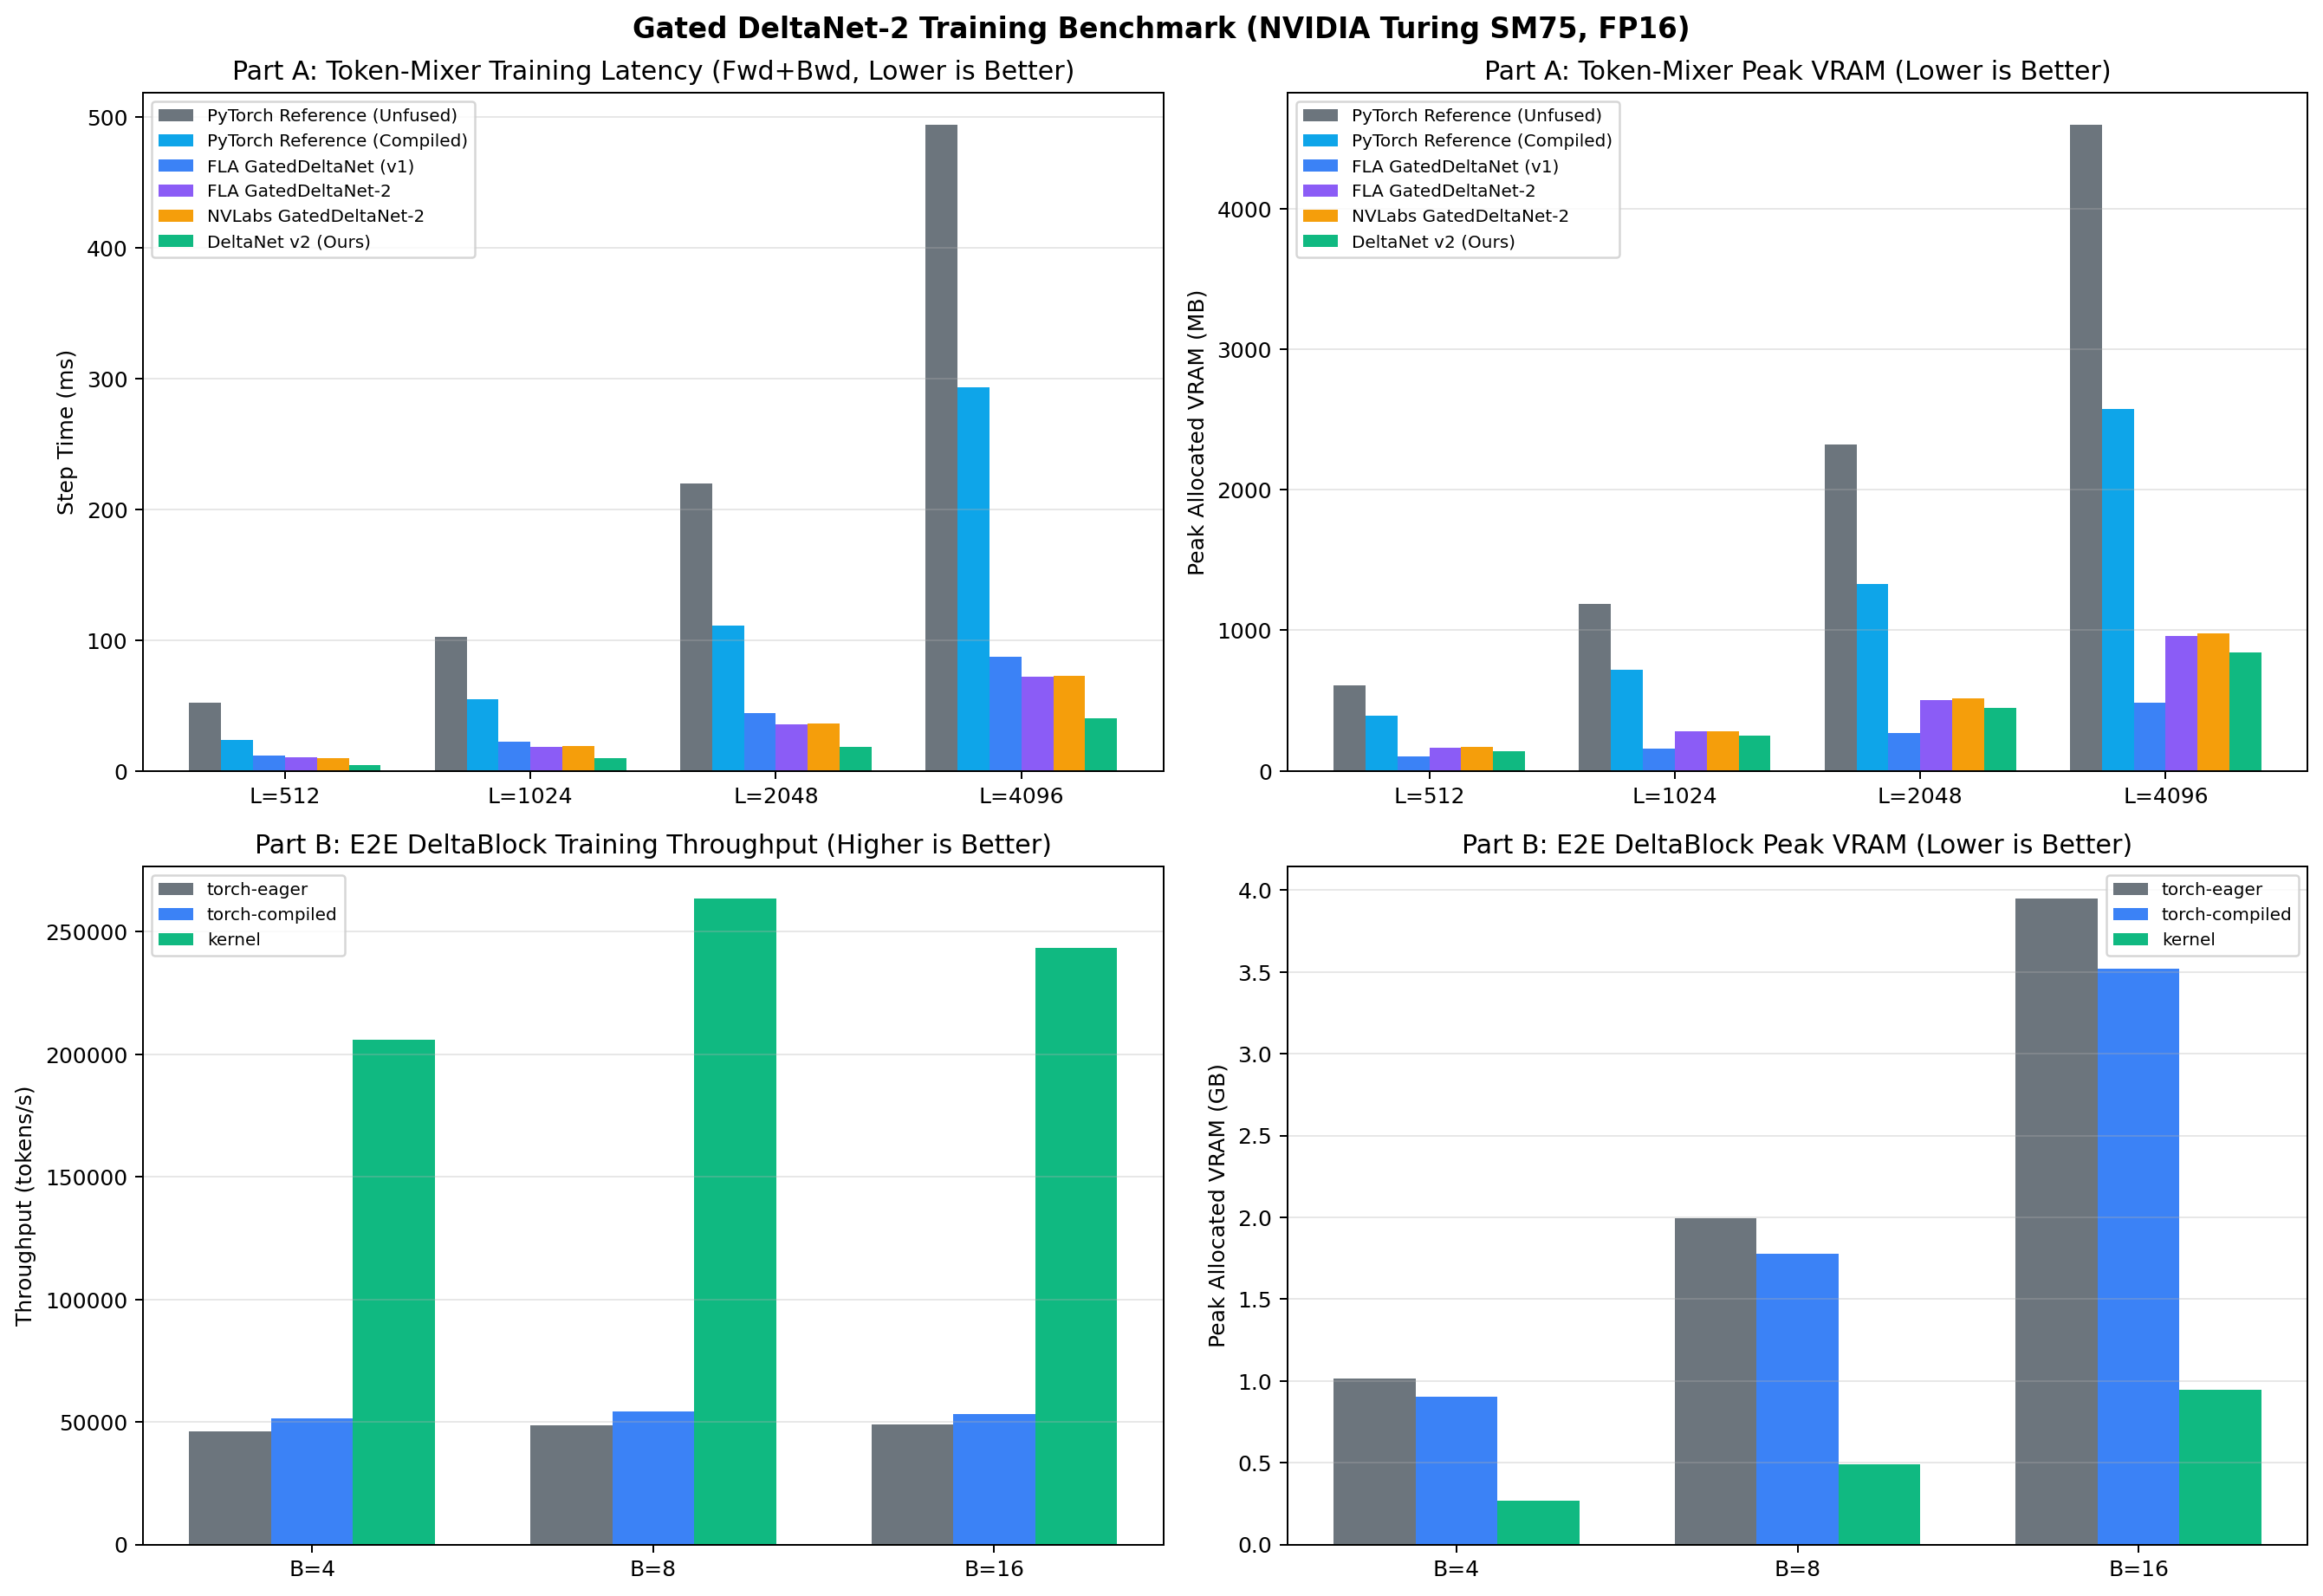

In [10]:
from IPython.display import Image, display
import os
if os.path.exists("assets/training_benchmark.png"):
    display(Image("assets/training_benchmark.png"))


In [11]:
!python -u tests/bench_inference.py \
    --dim 768 \
    --q-heads 8 \
    --kv-heads 8 \
    --batches 1,16,64,256,1024,2048 \
    --e2e-batches 16,64,256,1024 \
    --prefill-len 512 \
    --gen-steps 32 \
    --warmup 5 \
    --iters 20 \
    --save-plot assets/inference_benchmark.png


HARDWARE & RUNTIME ENVIRONMENT
PyTorch Version  : 2.14.1+cu130
CUDA Available   : True
Device Name      : Tesla T4
Compute Arch     : SM7.5
Total VRAM       : 14.56 GB
Multi-Processors : 40

BASELINE AVAILABILITY
[-] DeltaNet v2 (Ours)                 : INSTALLED
[-] DeltaNet v2 (PyTorch Reference)    : INSTALLED
[-] NVLabs GatedDeltaNet-2 (Official)  : INSTALLED
[-] FLA GatedDeltaNet-2 (FLA Library)  : INSTALLED
[-] FLA GatedDeltaNet (v1)             : INSTALLED


########################################################################
# PART A: AUTOREGRESSIVE DECODE (L = 1, PURE TOKEN MIXER VS BASELINES)
########################################################################

Config: d_model=768, H_q=8, H_kv=8, d_k=64, d_v=64, conv=True, dtype=torch.float16, device=cuda:0
Inference (Part A):   0% 0/6 [00:00<?, ?batch/s]
---> Benchmarking Batch Size B = 1 (L = 1) ...
  ✓ PyTorch Reference (Unfused): Lat=2.216ms | 451 tok/s | 3.0 GB/s
  ✓ PyTorch Reference (Compiled): Lat=1.334ms | 74

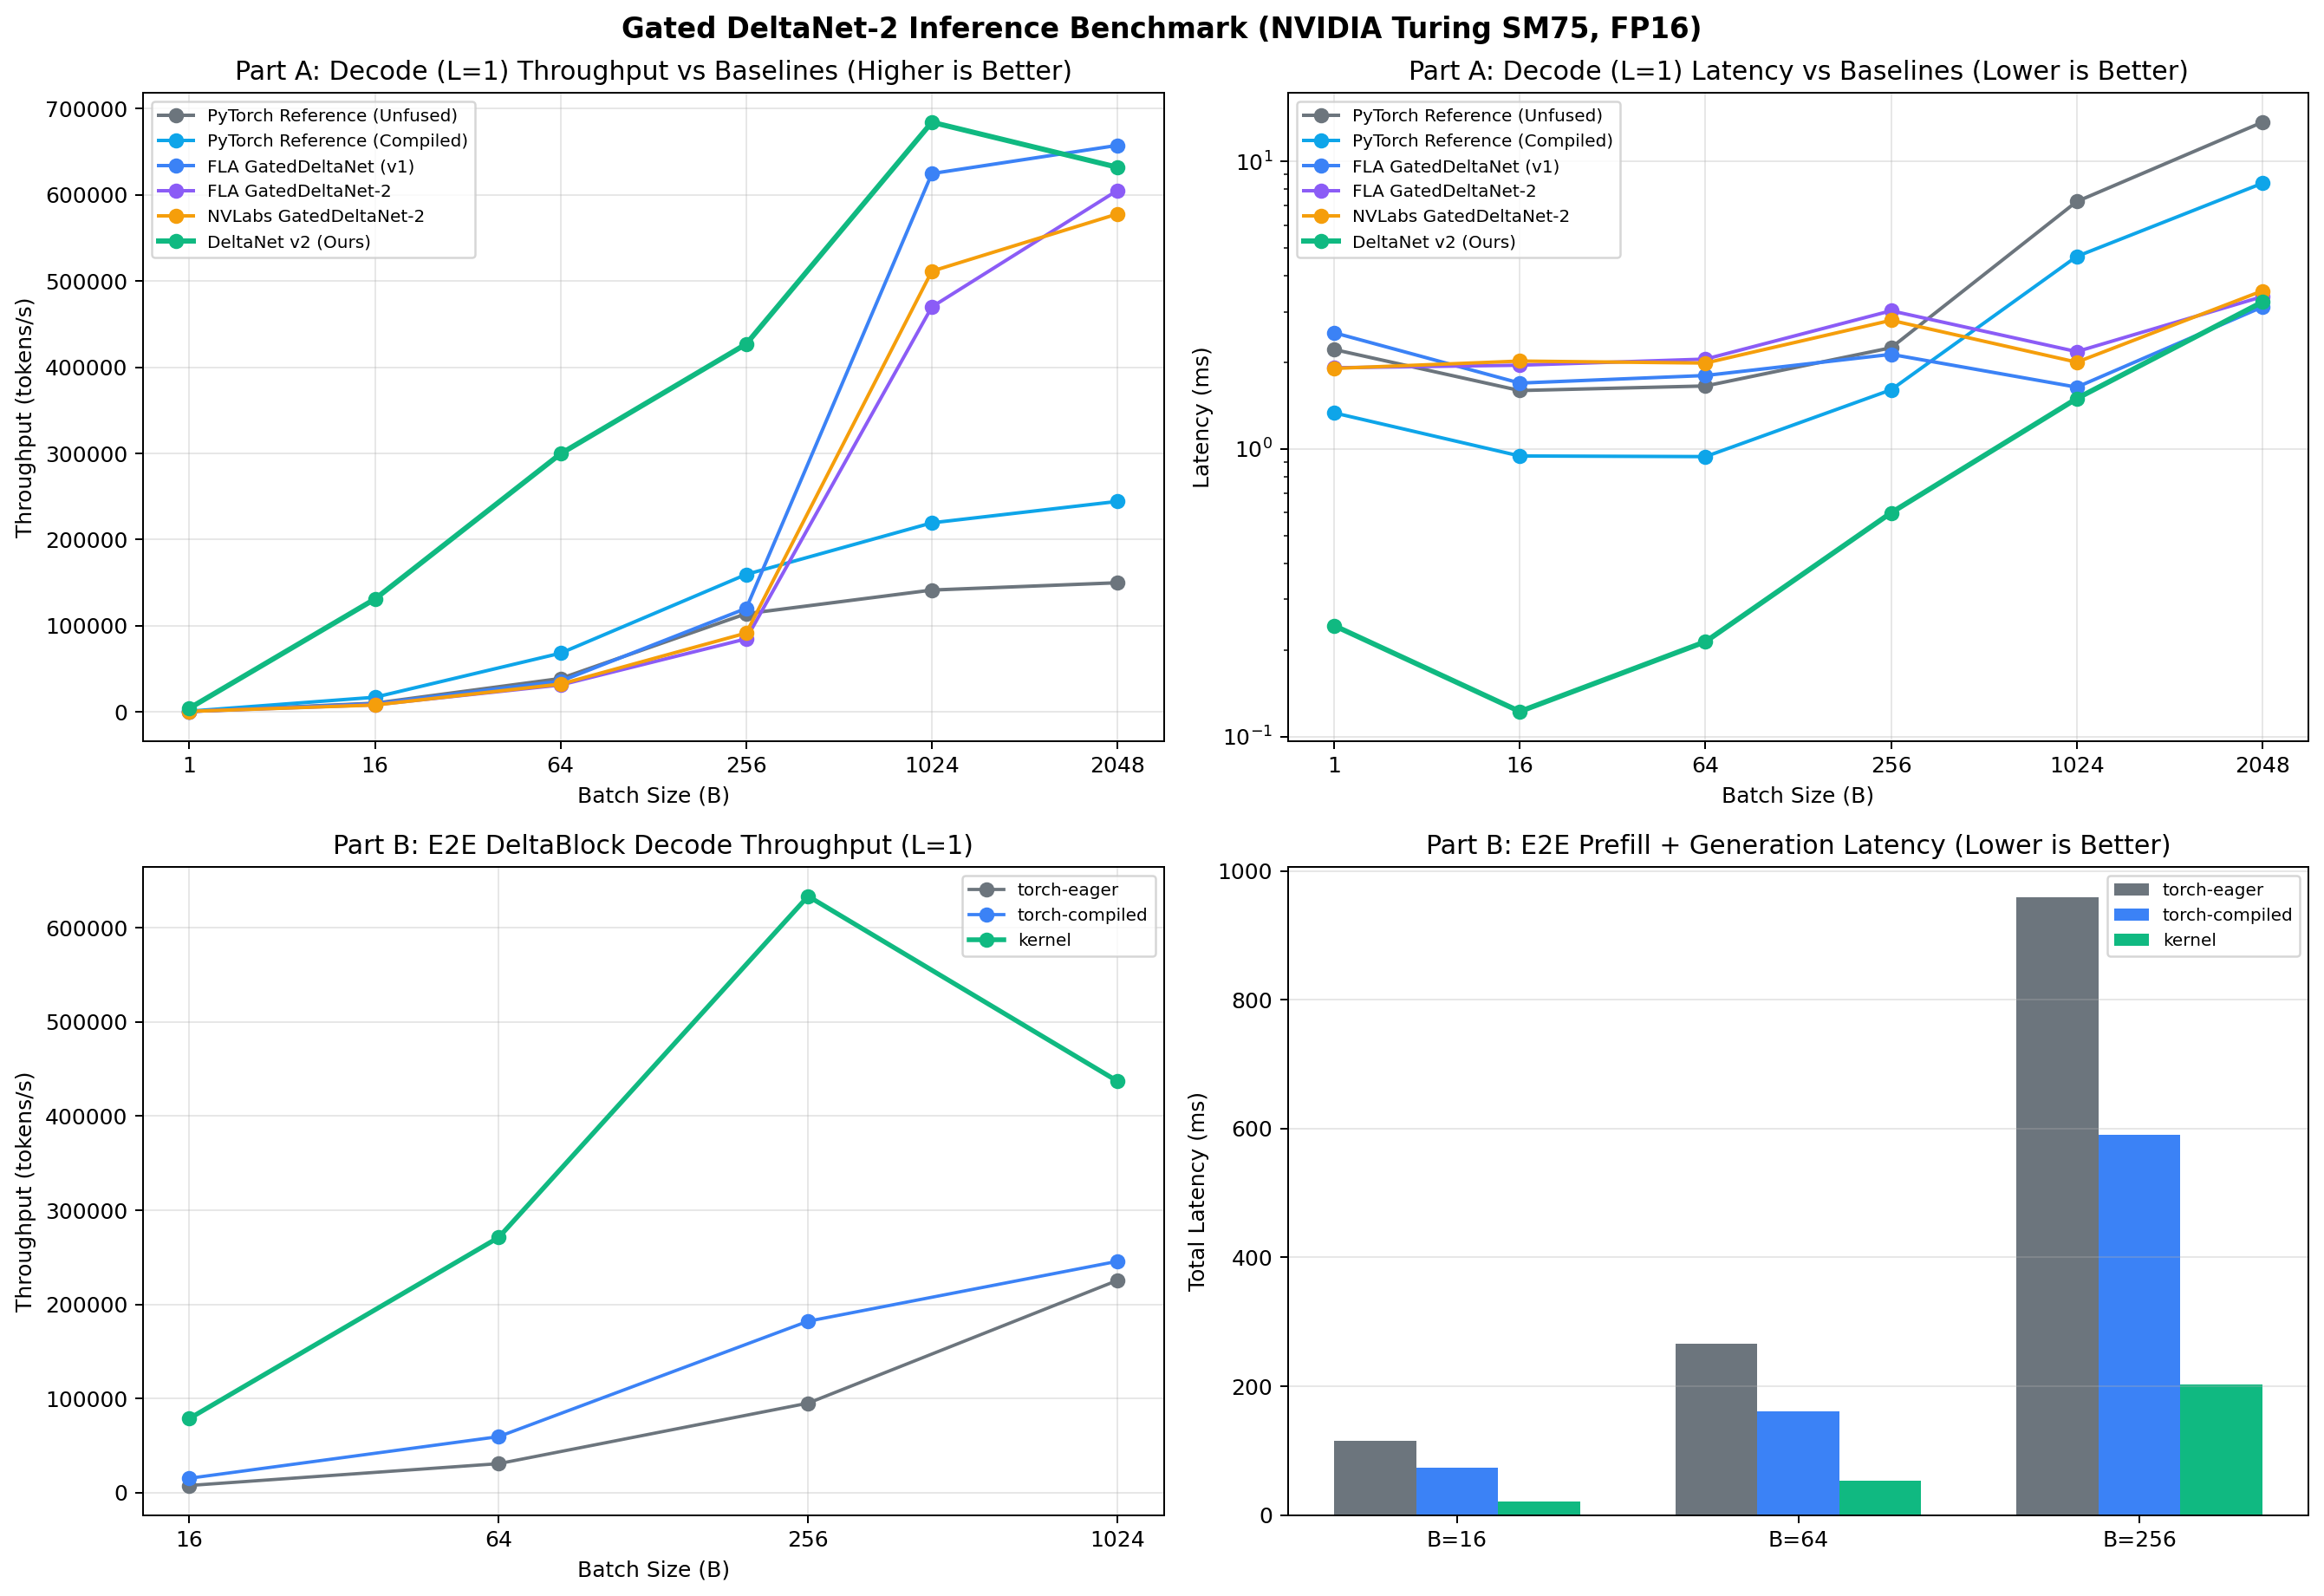

In [12]:
from IPython.display import Image, display
import os
if os.path.exists("assets/inference_benchmark.png"):
    display(Image("assets/inference_benchmark.png"))
